<a href="https://colab.research.google.com/github/192565074simats-code/MLA0201/blob/main/Experiment_19.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

BANK LOAN DATASET
    Income  Credit_Score  Loan_Amount  Employment_Years  Loan_Status
0    25000           550       200000                 1            0
1    30000           580       250000                 2            0
2    45000           650       300000                 4            1
3    50000           680       350000                 5            1
4    60000           720       400000                 6            1
5    70000           750       450000                 8            1
6    20000           500       180000                 1            0
7    35000           620       280000                 3            0
8    80000           780       500000                10            1
9    90000           800       550000                12            1
10   40000           640       320000                 4            1
11   55000           700       370000                 6            1
12   65000           730       420000                 7            1
13   28000      

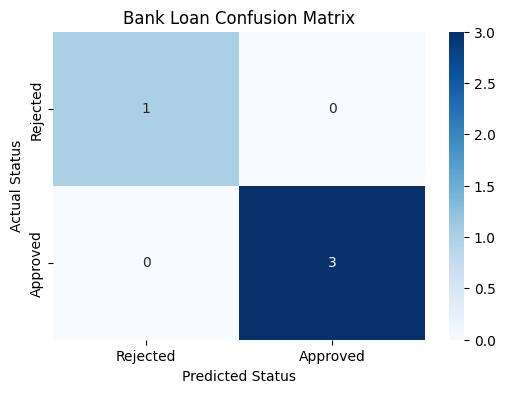

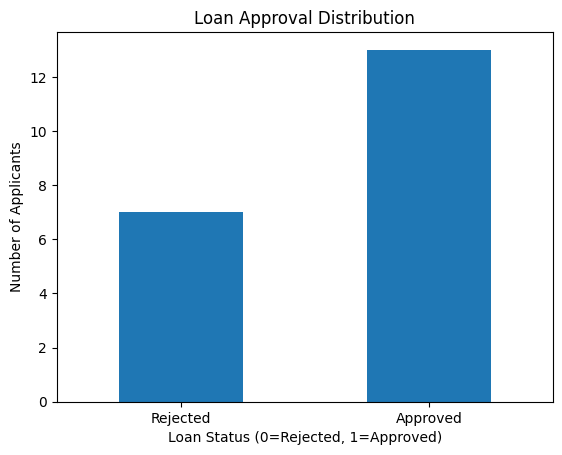

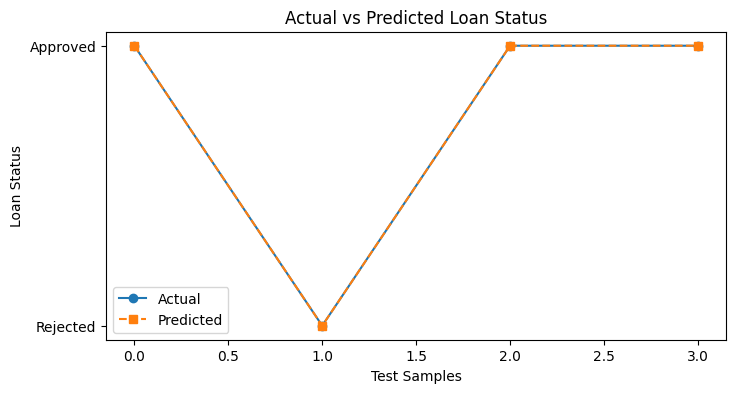

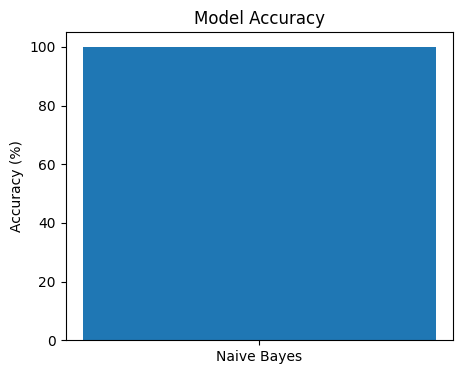


NEW LOAN APPLICATION
   Income  Credit_Score  Loan_Amount  Employment_Years
0   60000           750       300000                 6

Loan Status: Approved


In [1]:
# EXPERIMENT 19: BANK LOAN PREDICTION USING NAIVE BAYES

# Step 1: Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# Step 2: Create bank loan dataset
data = {
    'Income': [25000, 30000, 45000, 50000, 60000,
               70000, 20000, 35000, 80000, 90000,
               40000, 55000, 65000, 28000, 75000,
               32000, 85000, 48000, 95000, 22000],

    'Credit_Score': [550, 580, 650, 680, 720,
                     750, 500, 620, 780, 800,
                     640, 700, 730, 560, 770,
                     590, 790, 660, 820, 520],

    'Loan_Amount': [200000, 250000, 300000, 350000, 400000,
                    450000, 180000, 280000, 500000, 550000,
                    320000, 370000, 420000, 220000, 480000,
                    260000, 520000, 340000, 600000, 190000],

    'Employment_Years': [1, 2, 4, 5, 6, 8, 1, 3, 10, 12,
                         4, 6, 7, 2, 9, 3, 11, 5, 13, 1],

    'Loan_Status': [0, 0, 1, 1, 1, 1, 0, 0, 1, 1,
                    1, 1, 1, 0, 1, 0, 1, 1, 1, 0]
}

df = pd.DataFrame(data)

print("BANK LOAN DATASET")
print(df)

# Step 3: Separate input and output
X = df[['Income', 'Credit_Score',
        'Loan_Amount', 'Employment_Years']]

y = df['Loan_Status']

# Step 4: Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2,
    random_state=42, stratify=y
)

print("\nTraining Samples:", len(X_train))
print("Testing Samples:", len(X_test))

# Step 5: Train Naive Bayes model
model = GaussianNB()

model.fit(X_train, y_train)

print("\nNaive Bayes Model Trained Successfully!")

# Step 6: Predict loan status
y_pred = model.predict(X_test)

results = pd.DataFrame({
    'Actual Status': y_test.values,
    'Predicted Status': y_pred
})

print("\nLOAN PREDICTION RESULTS")
print(results)

# Step 7: Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("\nModel Accuracy:",
      round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=['Rejected', 'Approved'],
    zero_division=0
))

# Step 8: Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=['Rejected', 'Approved'],
    yticklabels=['Rejected', 'Approved']
)

plt.title("Bank Loan Confusion Matrix")
plt.xlabel("Predicted Status")
plt.ylabel("Actual Status")
plt.show()

# Step 9: Loan Status Distribution
df['Loan_Status'].value_counts().sort_index().plot(
    kind='bar'
)

plt.title("Loan Approval Distribution")
plt.xlabel("Loan Status (0=Rejected, 1=Approved)")
plt.ylabel("Number of Applicants")
plt.xticks([0, 1], ['Rejected', 'Approved'], rotation=0)
plt.show()

# Step 10: Actual vs Predicted Graph
plt.figure(figsize=(8, 4))

plt.plot(y_test.values, 'o-', label='Actual')
plt.plot(y_pred, 's--', label='Predicted')

plt.title("Actual vs Predicted Loan Status")
plt.xlabel("Test Samples")
plt.ylabel("Loan Status")
plt.yticks([0, 1], ['Rejected', 'Approved'])
plt.legend()
plt.show()

# Step 11: Accuracy Graph
plt.figure(figsize=(5, 4))

plt.bar(['Naive Bayes'], [accuracy * 100])

plt.title("Model Accuracy")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 105)
plt.show()

# Step 12: Predict New Loan Application
new_applicant = pd.DataFrame({
    'Income': [60000],
    'Credit_Score': [750],
    'Loan_Amount': [300000],
    'Employment_Years': [6]
})

prediction = model.predict(new_applicant)

print("\nNEW LOAN APPLICATION")
print(new_applicant)

if prediction[0] == 1:
    print("\nLoan Status: Approved")
else:
    print("\nLoan Status: Rejected")